1) FUNÇÃO DE TRANSFERÊNCIA
Média móvel (M = 8):  H(z) = (1/8) * sum_(k=0..7) z^-k
  Polos: 7 em z = 0  |  Zeros: raízes de z^8 = 1, exceto z = 1
  Zeros (ângulos, em unidades de pi): +0.250, +0.500, +0.750, +1.000, -0.750, -0.500, -0.250
IIR 1ª ordem (a = 0.8): H(z) = 0.20 / (1 - 0.8 z^-1)  (polo em z = 0.8)

2) RESPOSTA AO IMPULSO
MA: h[n] = 1/8 = 0.1250 para n = 0..7, zero fora disso
    erro vs. teoria: 0.00e+00
IIR: h[n] = 0.2 * 0.8^n u[n]; erro vs. teoria: 2.78e-17
    soma de h[n] (ganho DC): MA = 1.0000, IIR (40 amostras) = 0.9999

3) RESPOSTA EM FREQUÊNCIA - verificações numéricas
MA : definição x scipy.freqz      = 4.97e-16
MA : definição x forma fechada    = 4.45e-16
IIR: definição x scipy.freqz      = 2.99e-16
IIR: definição x DTFT de h[n]     = 5.58e-16

Y = X.H em regime permanente (MA): x = cos(0,1πn) + cos(0,6πn)
  |H(0,1π)| = 0.7599   |H(0,6π)| = 0.1469
  erro máx. |y[n] - saída prevista por H| = 2.48e-14

6.1) PARÂMETROS EXTRAÍDOS
Parâmetro                             

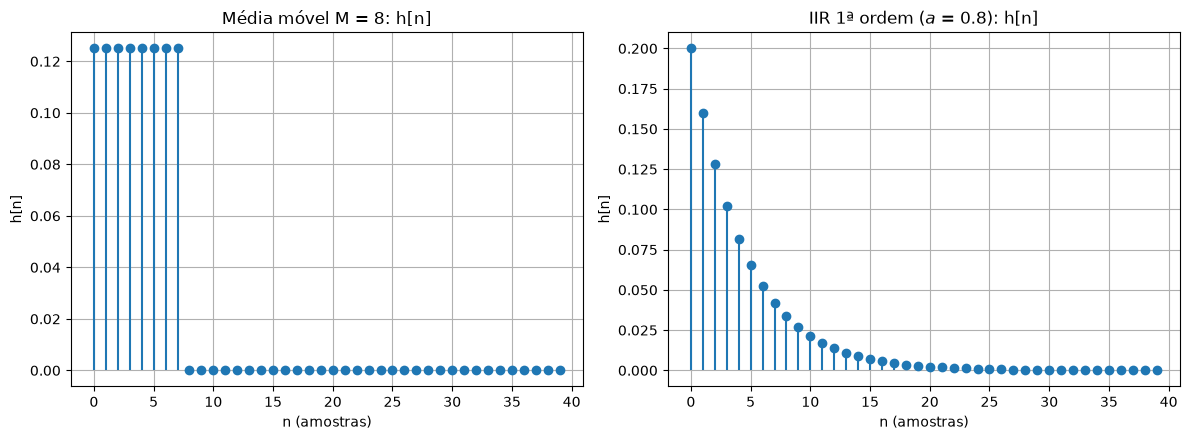

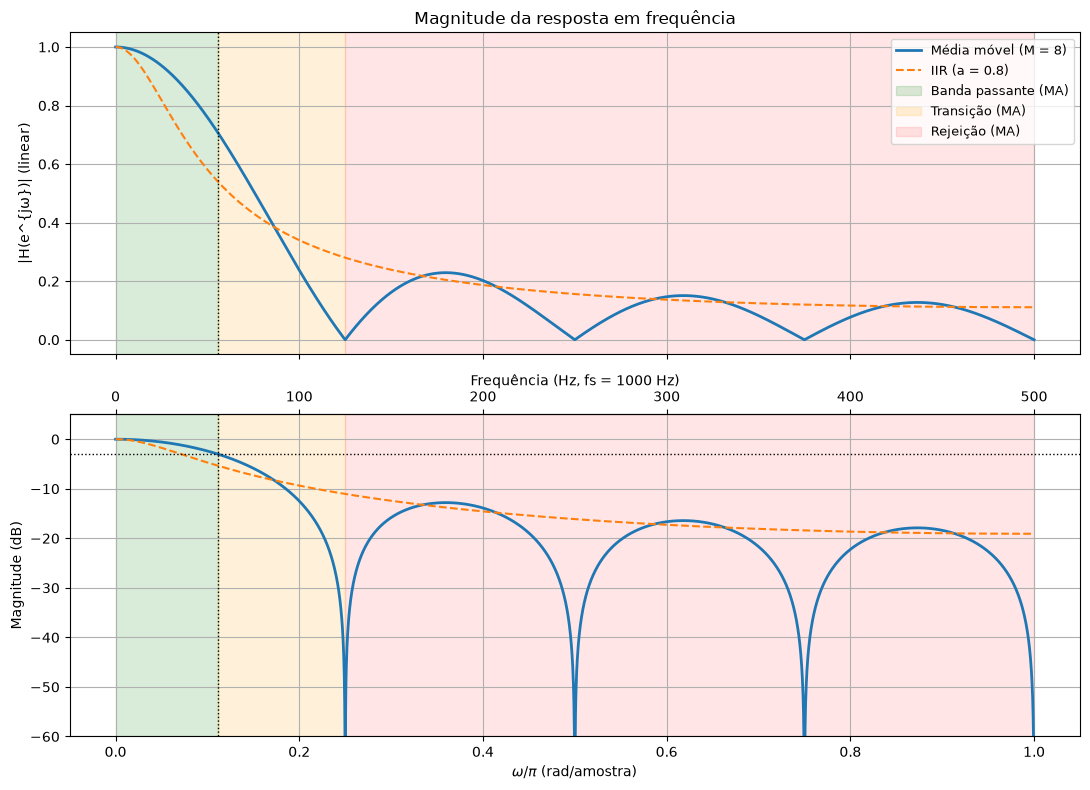

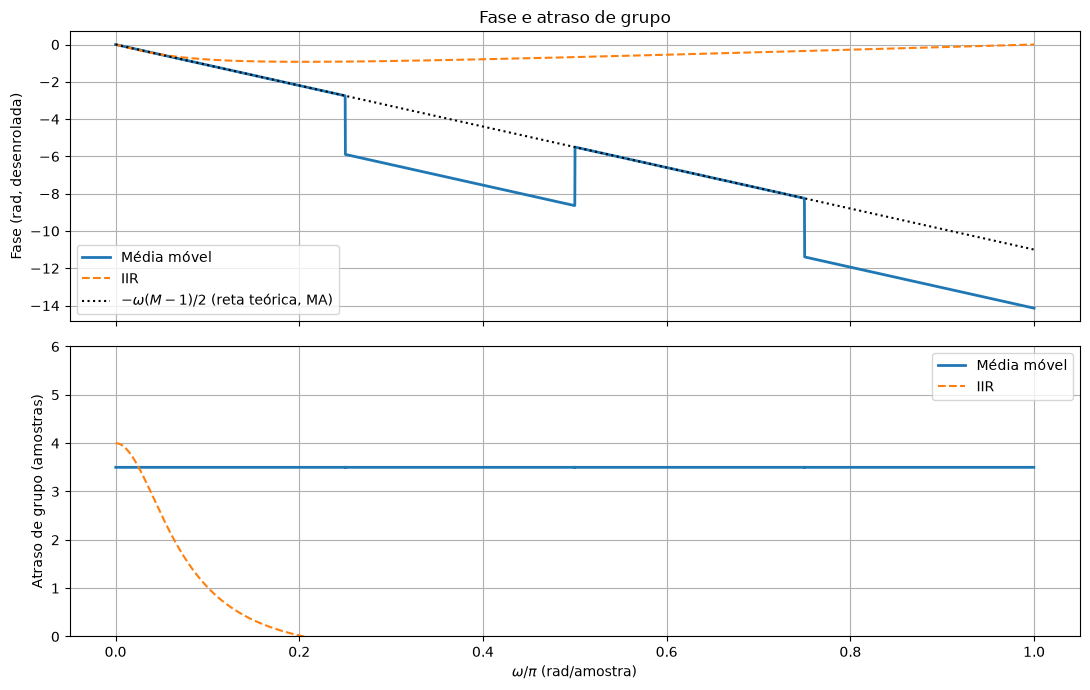

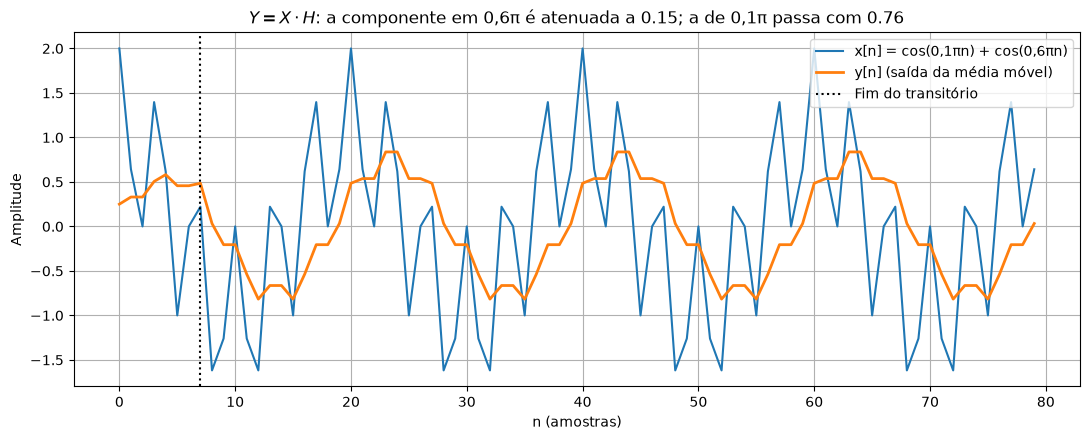

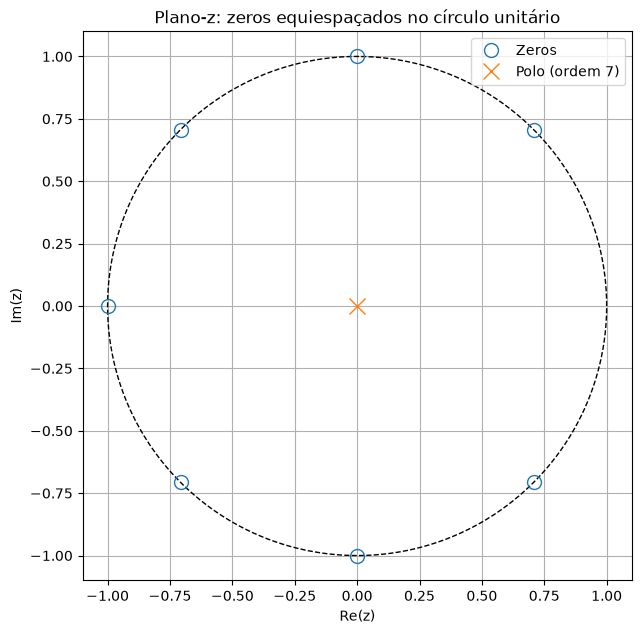

In [1]:
"""
Roteiro de Filtros Digitais - Tópico 2: Resposta em Frequência

Sistema investigado: média móvel de M = 8 amostras (FIR)

    H(z) = (1/M) * (1 + z^-1 + ... + z^-(M-1))
    y[n] = (1/M) * (x[n] + x[n-1] + ... + x[n-M+1])

Etapas da investigação (6.2 do roteiro):
    1. função de transferência          5. fase
    2. resposta ao impulso              6. regiões de maior passagem
    3. resposta em frequência           7. regiões de maior atenuação
    4. magnitude                        8. discussão dos resultados

Também são extraídos os parâmetros da seção 6.1 (banda passante, banda de
rejeição, banda de transição, frequência de corte, ganho, atenuação, ripple
e seletividade). Para contraste, um IIR de 1ª ordem, H(z) = (1-a)/(1-a z^-1),
é analisado com as mesmas métricas.

Convenção: ω em rad/amostra; o eixo em Hz usa fs = 1000 Hz (f = ω fs / 2π).
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

fs = 1000.0      # Hz, apenas para dar escala física ao eixo
M = 8            # comprimento da média móvel
a = 0.8          # polo do IIR de comparação

# ============================================================
# 1. FUNÇÃO DE TRANSFERÊNCIA (coeficientes b, a de H(z) = B(z)/A(z))
# ============================================================

b_ma = np.ones(M) / M
a_ma = np.array([1.0])

b_iir = np.array([1 - a])
a_iir = np.array([1.0, -a])

print("1) FUNÇÃO DE TRANSFERÊNCIA")
print("=" * 70)
print(f"Média móvel (M = {M}):  H(z) = (1/{M}) * sum_(k=0..{M-1}) z^-k")
print(f"  Polos: {M-1} em z = 0  |  Zeros: raízes de z^{M} = 1, exceto z = 1")
zeros_ma = np.exp(2j * np.pi * np.arange(1, M) / M)
print("  Zeros (ângulos, em unidades de pi): "
      + ", ".join(f"{np.angle(z) / np.pi:+.3f}" for z in zeros_ma))
print(f"IIR 1ª ordem (a = {a}): H(z) = {1 - a:.2f} / (1 - {a} z^-1)  "
      f"(polo em z = {a})\n")

# ============================================================
# 2. RESPOSTA AO IMPULSO
# ============================================================

N_h = 40
delta = np.zeros(N_h)
delta[0] = 1.0
h_ma = signal.lfilter(b_ma, a_ma, delta)
h_iir = signal.lfilter(b_iir, a_iir, delta)
h_iir_teorico = (1 - a) * a ** np.arange(N_h)

print("2) RESPOSTA AO IMPULSO")
print("=" * 70)
print(f"MA: h[n] = 1/{M} = {1 / M:.4f} para n = 0..{M-1}, zero fora disso")
print(f"    erro vs. teoria: "
      f"{np.max(np.abs(h_ma[:M] - 1 / M)) + np.max(np.abs(h_ma[M:])):.2e}")
print(f"IIR: h[n] = {1 - a:.1f} * {a}^n u[n]; "
      f"erro vs. teoria: {np.max(np.abs(h_iir - h_iir_teorico)):.2e}")
print(f"    soma de h[n] (ganho DC): MA = {h_ma.sum():.4f}, "
      f"IIR (40 amostras) = {h_iir.sum():.4f}\n")

# ============================================================
# 3. RESPOSTA EM FREQUÊNCIA H(e^jw) = H(z) em z = e^jw
# ============================================================

w = np.linspace(0, np.pi, 4001)


def H_direta(b, a_, w):
    """Avalia H(z) em z = e^{jw} pela definição (polinômios em e^{-jw})."""
    z_inv = np.exp(-1j * w)
    num = sum(bk * z_inv ** k for k, bk in enumerate(b))
    den = sum(ak * z_inv ** k for k, ak in enumerate(a_))
    return num / den


H_ma = H_direta(b_ma, a_ma, w)
H_iir = H_direta(b_iir, a_iir, w)

# Forma fechada da média móvel (núcleo de Dirichlet):
#   H(e^jw) = sin(M w/2) / (M sin(w/2)) * e^{-j w (M-1)/2}
with np.errstate(invalid="ignore", divide="ignore"):
    H_ma_fechada = (np.sin(M * w / 2) / (M * np.sin(w / 2))
                    * np.exp(-1j * w * (M - 1) / 2))
H_ma_fechada[0] = 1.0   # limite em w = 0

# Validação independente com scipy.signal.freqz
_, H_ma_scipy = signal.freqz(b_ma, a_ma, worN=w)
_, H_iir_scipy = signal.freqz(b_iir, a_iir, worN=w)

# Validação via DTFT de h[n] (soma da definição, cauda desprezível no IIR)
n_h = np.arange(400)
h_iir_longa = (1 - a) * a ** n_h
H_iir_dtft = np.array([np.sum(h_iir_longa * np.exp(-1j * wk * n_h))
                       for wk in w])

print("3) RESPOSTA EM FREQUÊNCIA - verificações numéricas")
print("=" * 70)
print(f"MA : definição x scipy.freqz      = "
      f"{np.max(np.abs(H_ma - H_ma_scipy)):.2e}")
print(f"MA : definição x forma fechada    = "
      f"{np.max(np.abs(H_ma - H_ma_fechada)):.2e}")
print(f"IIR: definição x scipy.freqz      = "
      f"{np.max(np.abs(H_iir - H_iir_scipy)):.2e}")
print(f"IIR: definição x DTFT de h[n]     = "
      f"{np.max(np.abs(H_iir - H_iir_dtft)):.2e}\n")

# Verificação de Y(e^jw) = X(e^jw) H(e^jw): senoides em regime permanente
w1, w2 = 0.1 * np.pi, 0.6 * np.pi
n = np.arange(400)
x = np.cos(w1 * n) + np.cos(w2 * n)
y = signal.lfilter(b_ma, a_ma, x)
Hw1 = H_direta(b_ma, a_ma, np.array([w1]))[0]
Hw2 = H_direta(b_ma, a_ma, np.array([w2]))[0]
y_teorico = (np.abs(Hw1) * np.cos(w1 * n + np.angle(Hw1))
             + np.abs(Hw2) * np.cos(w2 * n + np.angle(Hw2)))
reg = n >= M - 1    # após o transitório (FIR: M-1 amostras)
print("Y = X.H em regime permanente (MA): x = cos(0,1πn) + cos(0,6πn)")
print(f"  |H(0,1π)| = {abs(Hw1):.4f}   |H(0,6π)| = {abs(Hw2):.4f}")
print(f"  erro máx. |y[n] - saída prevista por H| = "
      f"{np.max(np.abs(y[reg] - y_teorico[reg])):.2e}\n")

# ============================================================
# 4-5. MAGNITUDE E FASE
# ============================================================

mag_ma, mag_iir = np.abs(H_ma), np.abs(H_iir)
with np.errstate(divide="ignore"):
    mag_ma_db = 20 * np.log10(np.maximum(mag_ma, 1e-12))
    mag_iir_db = 20 * np.log10(np.maximum(mag_iir, 1e-12))
fase_ma = np.unwrap(np.angle(H_ma))
fase_iir = np.unwrap(np.angle(H_iir))

# Atraso de grupo: -d(fase)/dw  (MA linear: constante = (M-1)/2 amostras)
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # singularidade nos zeros do MA
    _, gd_ma = signal.group_delay((b_ma, a_ma), w=w)
    _, gd_iir = signal.group_delay((b_iir, a_iir), w=w)
gd_ma = np.where(mag_ma > 1e-6, gd_ma, np.nan)   # indefinido nos nulos

# ============================================================
# 6-7. PARÂMETROS (seção 6.1)
# ============================================================
# Definições adotadas:
#   ganho         : |H| em w = 0 (ganho DC)
#   freq. de corte: primeiro w com |H| = ganho/sqrt(2) (-3 dB)
#   banda passante: 0 <= w <= wc
#   banda de rejeição (MA): w >= w_rej, com w_rej = 2π/M (1º zero de |H|)
#   banda de transição: wc < w < w_rej
#   atenuação na rejeição: -max|H| (dB) em w >= w_rej
#   ripple: oscilação de |H| (monotonicidade na passante; picos na rejeição)
#   seletividade: razão wc / (w_rej - wc) (quanto maior, mais seletivo)

def parametros(mag, w, w_rej):
    ganho = mag[0]
    alvo = ganho / np.sqrt(2)
    i_c = np.argmax(mag <= alvo)
    wc = w[i_c]
    passante = w <= wc
    monotona = bool(np.all(np.diff(mag[passante]) <= 1e-12))
    rej = w >= w_rej
    pico_rej = mag[rej].max()
    atenuacao_rej = -20 * np.log10(pico_rej)
    # picos dos lóbulos laterais (máximos locais na região de rejeição)
    idx = np.where((mag[1:-1] > mag[:-2]) & (mag[1:-1] > mag[2:]))[0] + 1
    lobulos = [mag[i] for i in idx if w[i] >= w_rej]
    return dict(ganho=ganho, wc=wc, monotona=monotona,
                w_rej=w_rej, atenuacao_rej=atenuacao_rej,
                lobulos_db=[20 * np.log10(l) for l in lobulos],
                seletividade=wc / (w_rej - wc))


w_rej_ma = 2 * np.pi / M
par_ma = parametros(mag_ma, w, w_rej_ma)

# IIR não tem zeros no círculo unitário; adota-se como borda da rejeição a
# mesma frequência do MA, para comparar atenuação na mesma região.
par_iir = parametros(mag_iir, w, w_rej_ma)

print("6.1) PARÂMETROS EXTRAÍDOS")
print("=" * 78)
print(f"{'Parâmetro':<38}{'Média móvel M=8':>20}{'IIR a=0,8':>20}")
print("-" * 78)


print(f"{'Ganho DC |H(1)|':<38}{par_ma['ganho']:>20.4f}"
      f"{par_iir['ganho']:>20.4f}")
print(f"{'Freq. de corte (-3 dB), rad/amostra':<38}"
      f"{par_ma['wc']:>20.4f}{par_iir['wc']:>20.4f}")
print(f"{'Freq. de corte, Hz (fs=1000)':<38}"
      f"{par_ma['wc'] * fs / (2 * np.pi):>20.1f}"
      f"{par_iir['wc'] * fs / (2 * np.pi):>20.1f}")
print(f"{'Início da rejeição (1º zero MA), rad':<38}"
      f"{w_rej_ma:>20.4f}{w_rej_ma:>20.4f}")
print(f"{'Largura da transição, rad/amostra':<38}"
      f"{w_rej_ma - par_ma['wc']:>20.4f}{w_rej_ma - par_iir['wc']:>20.4f}")
print(f"{'Seletividade wc/(w_rej-wc)':<38}"
      f"{par_ma['seletividade']:>20.3f}{par_iir['seletividade']:>20.3f}")
print(f"{'Atenuação mín. na rejeição (dB)':<38}"
      f"{par_ma['atenuacao_rej']:>20.2f}{par_iir['atenuacao_rej']:>20.2f}")
print(f"{'Passante monotônica (sem ripple)':<38}"
      f"{str(par_ma['monotona']):>20}{str(par_iir['monotona']):>20}")
for nome, d in (("MA", par_ma), ("IIR", par_iir)):
    print(f"  Picos de lóbulo na rejeição ({nome}, dB): "
          + (", ".join(f"{v:.1f}" for v in d["lobulos_db"]) or "nenhum"))

i_pi2 = np.argmin(np.abs(w - np.pi / 2))
def fmt_db(m):
    return "-inf (nulo)" if m < 1e-9 else f"{20 * np.log10(m):.2f}"


print(f"{'|H| em w = π/2 (dB)':<38}{fmt_db(mag_ma[i_pi2]):>20}"
      f"{fmt_db(mag_iir[i_pi2]):>20}")
print(f"{'|H| em w = π (dB)':<38}{fmt_db(mag_ma[-1]):>20}"
      f"{fmt_db(mag_iir[-1]):>20}")
print(f"{'Atraso de grupo em w ≈ 0 (amostras)':<38}"
      f"{gd_ma[1]:>20.3f}{gd_iir[1]:>20.3f}")
print(f"  MA: fase linear, atraso constante (M-1)/2 = {(M - 1) / 2} amostras")
print(f"  Zeros de |H| do MA em w = 2πk/M: "
      + ", ".join(f"{k / (M / 2):.2f}π" for k in range(1, M // 2 + 1)))

# Regiões de maior passagem e de maior atenuação
print("\n6-7) REGIÕES DE PASSAGEM E ATENUAÇÃO (MA)")
print("=" * 70)
print(f"Maior passagem : 0 <= w <= {par_ma['wc']:.3f} rad/amostra "
      f"(|H| >= {par_ma['ganho'] / np.sqrt(2):.3f})")
print(f"Transição      : {par_ma['wc']:.3f} < w < {w_rej_ma:.3f}")
print(f"Maior atenuação: w >= {w_rej_ma:.3f}, com zeros em "
      f"{', '.join(f'{k / (M / 2):.2f}π' for k in range(1, M // 2 + 1))}")
print(f"Pior atenuação na rejeição: {par_ma['atenuacao_rej']:.2f} dB "
      f"(primeiro lóbulo lateral)")

# ============================================================
# FIGURAS
# ============================================================

f_hz = w * fs / (2 * np.pi)
wc_ma = par_ma["wc"]

# Fig. 1: resposta ao impulso
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
eixos[0].stem(np.arange(N_h), h_ma, basefmt=" ")
eixos[0].set_title(f"Média móvel M = {M}: h[n]")
eixos[1].stem(np.arange(N_h), h_iir, basefmt=" ")
eixos[1].set_title(rf"IIR 1ª ordem ($a$ = {a}): h[n]")
for ax in eixos:
    ax.set_xlabel("n (amostras)")
    ax.set_ylabel("h[n]")
    ax.grid(True)
plt.tight_layout()
plt.show()

# Fig. 2: magnitude (linear e dB) com regiões identificadas
fig, eixos = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for ax, (m_ma, m_iir, rot) in zip(
        eixos, [(mag_ma, mag_iir, "|H(e^{jω})| (linear)"),
                (mag_ma_db, mag_iir_db, "Magnitude (dB)")]):
    ax.plot(w / np.pi, m_ma, label=f"Média móvel (M = {M})", linewidth=2)
    ax.plot(w / np.pi, m_iir, "--", label=f"IIR (a = {a})", linewidth=1.5)
    ax.axvspan(0, wc_ma / np.pi, color="green", alpha=0.15,
               label="Banda passante (MA)")
    ax.axvspan(wc_ma / np.pi, w_rej_ma / np.pi, color="orange", alpha=0.15,
               label="Transição (MA)")
    ax.axvspan(w_rej_ma / np.pi, 1, color="red", alpha=0.10,
               label="Rejeição (MA)")
    ax.axvline(wc_ma / np.pi, color="k", linestyle=":", linewidth=1)
    ax.set_ylabel(rot)
    ax.grid(True)
eixos[0].set_title("Magnitude da resposta em frequência")
eixos[0].legend(loc="upper right", fontsize=9)
eixos[1].axhline(-3.01, color="k", linestyle=":", linewidth=1)
eixos[1].set_ylim(-60, 5)
eixos[1].set_xlabel(r"$\omega/\pi$ (rad/amostra)")
sec = eixos[1].secondary_xaxis(
    "top", functions=(lambda x: x * fs / 2, lambda x: x * 2 / fs))
sec.set_xlabel("Frequência (Hz, fs = 1000 Hz)")
plt.tight_layout()
plt.show()

# Fig. 3: fase e atraso de grupo
fig, eixos = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
eixos[0].plot(w / np.pi, fase_ma, linewidth=2, label="Média móvel")
eixos[0].plot(w / np.pi, fase_iir, "--", label="IIR")
eixos[0].plot(w / np.pi, -w * (M - 1) / 2, ":", color="k",
              label=r"$-\omega (M-1)/2$ (reta teórica, MA)")
eixos[0].set_ylabel("Fase (rad, desenrolada)")
eixos[0].set_title("Fase e atraso de grupo")
eixos[0].legend()
eixos[1].plot(w[1:] / np.pi, gd_ma[1:], linewidth=2, label="Média móvel")
eixos[1].plot(w[1:] / np.pi, gd_iir[1:], "--", label="IIR")
eixos[1].set_ylabel("Atraso de grupo (amostras)")
eixos[1].set_xlabel(r"$\omega/\pi$ (rad/amostra)")
eixos[1].set_ylim(0, 6)
eixos[1].legend()
for ax in eixos:
    ax.grid(True)
plt.tight_layout()
plt.show()

# Fig. 4: Y = X.H no tempo (duas senoides)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(n[:80], x[:80], label="x[n] = cos(0,1πn) + cos(0,6πn)")
ax.plot(n[:80], y[:80], label="y[n] (saída da média móvel)", linewidth=2)
ax.axvline(M - 1, color="k", linestyle=":", label="Fim do transitório")
ax.set_xlabel("n (amostras)")
ax.set_ylabel("Amplitude")
ax.set_title(r"$Y = X\cdot H$: a componente em 0,6π é atenuada "
             rf"a {abs(Hw2):.2f}; a de 0,1π passa com {abs(Hw1):.2f}")
ax.legend(loc="upper right")
ax.grid(True)
plt.tight_layout()
plt.show()

# Fig. 5: plano-z (polos e zeros) do MA
fig, ax = plt.subplots(figsize=(6.5, 6.5))
th = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(th), np.sin(th), "k--", linewidth=1)
ax.plot(zeros_ma.real, zeros_ma.imag, "o", markerfacecolor="none",
        markersize=10, label="Zeros")
ax.plot([0], [0], "x", markersize=12, label=f"Polo (ordem {M-1})")
ax.set_aspect("equal")
ax.set_xlabel("Re(z)")
ax.set_ylabel("Im(z)")
ax.set_title("Plano-z: zeros equiespaçados no círculo unitário")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()